# Project 5: Generative AI Applications
## Generating Emily Dickinson–style poetry by fine-tuning GPT-2

**Generative approach:** Transformer-based text generation. A pretrained GPT-2 (124M parameters, decoder-only Transformer) is fine-tuned with a hand-written PyTorch training loop, using the Hugging Face Transformers library for the model and tokenizer.

**Goal of the system:** given the **first line of a poem**, generate a continuation (the next lines and stanzas) that reads like the poems of Emily Dickinson as her first editors published them in 1890–1896.

**Data:** *Poems by Emily Dickinson, Three Series, Complete* (Project Gutenberg eBook #12242). These are 446 short lyric poems by a real, human author, and the text is in the public domain. The prompts are the real first lines of held-out Dickinson poems, so no prompt was written by an AI tool.

**Notebook outline**
0. Setup and reproducibility
1. Task definition and choice of approach (Task 1)
2. Load and inspect the data (Task 2)
3. Model, training and diagnostics (Task 3)
4. Generate and evaluate outputs (Task 4)
   - 4.1 Held-out perplexity: pretrained vs. fine-tuned
   - 4.2 Generated samples
   - 4.3 Style statistics
   - 4.4 Decoding strategy and a failure case (greedy repetition)
   - 4.5 Memorization check
   - 4.6 Qualitative evaluation
5. Notebook summary (Task 5)

## 0. Setup and reproducibility

All settings live in one `CONFIG` dictionary. Seeds are fixed for Python, NumPy and PyTorch. Every sampled generation call also re-seeds with its own seed, so each sample can be reproduced on its own. The device is chosen as CUDA → Apple MPS → CPU.

In [1]:
import re, json, math, time, random, copy
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers
from transformers import GPT2LMHeadModel, GPT2TokenizerFast, get_linear_schedule_with_warmup

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("data")
FIG_DIR = Path("outputs/figures")
MET_DIR = Path("outputs/metrics")
GEN_DIR = Path("outputs/generations")
for d in (FIG_DIR, MET_DIR, GEN_DIR):
    d.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    model_name="gpt2",        # GPT-2 small, 124M parameters
    seed=42,
    split_frac=(0.8, 0.1, 0.1),  # train / validation / test, split by POEM
    block_size=128,           # tokens per training sequence
    batch_size=8,
    lr=5e-5,
    weight_decay=0.01,
    warmup_frac=0.1,          # share of steps with linear LR warm-up
    epochs=8,
    grad_clip=1.0,
    max_new_tokens=80,        # generation length
    temperature=0.8,          # nucleus-sampling settings used for evaluation
    top_p=0.9,
)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(CONFIG["seed"])

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"device: {device}")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | "
      f"numpy {np.__version__} | pandas {pd.__version__}")
print(json.dumps(CONFIG, indent=1))

W1126 14:41:31.556000 5361 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps
torch 2.15.0 | transformers 5.24.1 | numpy 2.5.5 | pandas 3.1.1
{
 "model_name": "gpt2",
 "seed": 42,
 "split_frac": [
  0.8,
  0.1,
  0.1
 ],
 "block_size": 128,
 "batch_size": 8,
 "lr": 5e-05,
 "weight_decay": 0.01,
 "warmup_frac": 0.1,
 "epochs": 8,
 "grad_clip": 1.0,
 "max_new_tokens": 80,
 "temperature": 0.8,
 "top_p": 0.9
}


## 1. Task definition and choice of approach (Task 1)

**Generative task.** *Conditional poem continuation.* The input is the first line of a poem. The output is a continuation in the style of the corpus: short lines, four-line stanzas, a hymn-like meter, slant rhyme, dashes, and compressed images of nature, death, faith and the inner life.

**What the system produces:** plain-text verse, up to 80 GPT-2 tokens long (about 50–60 words, the length of a typical poem in this corpus).

**Why a Transformer, and why fine-tune a pretrained GPT-2.**
- Poetry is a sequence, and its structure depends on context several lines back: the rhyme on line 4 answers line 2, and the stanza shape repeats. Self-attention lets every token attend to all earlier tokens in the window directly. That suits these long-range dependencies better than a recurrent model's step-by-step memory.
- GPT-2 is a *decoder-only, causal* language model. It is trained to predict the next token, which is exactly the operation needed to continue a poem from its first line.
- The corpus is small: about 43,000 GPT-2 tokens. That is far too little to train a language model from scratch, which would only learn to copy. Fine-tuning a model that already knows English grammar and vocabulary lets the small corpus teach *style* rather than language. This is the transfer-learning argument for fine-tuning pretrained language models.
- GAN and VAE options in the brief target images. GANs are also hard to apply to discrete tokens, because sampling words is not differentiable. So a Transformer is the natural choice for text.
- GPT-2 small runs and fine-tunes in minutes on a laptop GPU (Apple M4).

**Dataset or prompt source requirements.**

| Requirement | How it is met |
|---|---|
| Real, human-created | Poems written by Emily Dickinson (1830–1886), as edited by M. L. Todd and T. W. Higginson (1890, 1891, 1896) |
| Publicly available, documented | Project Gutenberg eBook #12242, file `data/12242-0.txt`. Source and checksum are in `data/README.md` |
| Appropriate for academic use | Public-domain text in the United States |
| Not synthetic or AI-generated; prompts not AI-written | The training text and every prompt (first lines of held-out poems) are Dickinson's own words |
| Not reused from an earlier capstone | Earlier projects used UCI Student Performance, UCI Adult and EuroSAT |

## 2. Load and inspect the data (Task 2)

### 2.1 Raw file

The Gutenberg file holds the three *Series* of poems published after Dickinson's death. Each Series has an editors' preface, then four thematic sections (Life, Love, Nature, Time and Eternity). Each poem is numbered with a Roman numeral and may have an editor-supplied title and a bracketed editorial note.

In [2]:
RAW_PATH = DATA_DIR / "12242-0.txt"
raw = RAW_PATH.read_text(encoding="utf-8").replace("\r\n", "\n")
print(f"file: {RAW_PATH}  |  {len(raw):,} characters  |  {raw.count(chr(10)):,} lines")
print("-" * 70)
start = raw.index("I. LIFE.")
print(raw[start:start + 900])

file: data/12242-0.txt  |  176,638 characters  |  10,312 lines
----------------------------------------------------------------------
I. LIFE.


I.

SUCCESS.

[Published in "A Masque of Poets"
at the request of "H.H.," the author's
fellow-townswoman and friend.]

Success is counted sweetest
By those who ne'er succeed.
To comprehend a nectar
Requires sorest need.

Not one of all the purple host
Who took the flag to-day
Can tell the definition,
So clear, of victory,

As he, defeated, dying,
On whose forbidden ear
The distant strains of triumph
Break, agonized and clear!





II.

Our share of night to bear,
Our share of morning,
Our blank in bliss to fill,
Our blank in scorning.

Here a star, and there a star,
Some lose their way.
Here a mist, and there a mist,
Afterwards -- day!





III.

ROUGE ET NOIR.

Soul, wilt thou toss again?
By just such a hazard
Hundreds have lost, indeed,
But tens have won an all.

Angels' breathless ballot
Lingers to record thee;
Imps in eager caucus
Raffle f

### 2.2 Parse the file into one record per poem

The parser walks the file line by line. It does the following:
- skips the Gutenberg header and footer, the three prefaces and the transcriber's notes;
- tracks the Series (1–3) and thematic section;
- starts a new poem at each Roman-numeral line;
- keeps the editor's title as **metadata only**, because titles were added by the editors and not by Dickinson;
- drops bracketed editorial notes and `* * *` separators;
- strips leading indentation and keeps line and stanza breaks, because they are part of the form the model should learn.

In [3]:
SECTION_RE = re.compile(r"^(I|II|III|IV)\. (LIFE|LOVE|NATURE|TIME AND ETERNITY)\.$")
NUMBER_RE = re.compile(r"^[IVXLC]+\.$")

def parse_poems(text):
    series, section, poems, cur, in_body = 0, None, [], None, False
    for line in text.split("\n"):
        s = line.strip()
        if s.startswith("*** END OF"):
            break
        if s == "POEMS" or s.startswith("PREFACE"):      # a new Series begins: preface is not poetry
            if cur: poems.append(cur); cur = None
            in_body = False
            continue
        m = SECTION_RE.match(s)
        if m:                                             # e.g. "II. LOVE."
            if cur: poems.append(cur); cur = None
            series += m.group(2) == "LIFE"
            section, in_body = m.group(2).title(), True
            continue
        if not in_body:
            continue
        if NUMBER_RE.match(s):                            # poem number, e.g. "XIV."
            if cur and cur["title"] and not any(cur["lines"]):
                continue                                  # sub-numbered poem under a shared title
            if cur: poems.append(cur)
            cur = dict(series=series, section=section, number=s[:-1], title=None, lines=[], note=False)
            continue
        if cur is None:
            continue
        if cur["note"]:                                   # inside a multi-line [editorial note]
            cur["note"] = not s.endswith("]")
            continue
        if s.startswith("["):
            cur["note"] = not s.endswith("]")
            continue
        if s and set(s) <= set("* "):                     # "*  *  *" separator
            continue
        if not any(cur["lines"]) and cur["title"] is None and s and s == s.upper() and re.search("[A-Z]", s):
            cur["title"] = s.rstrip(".")                  # editor-supplied title
            continue
        cur["lines"].append(s)
    if cur:
        poems.append(cur)

    rows = []
    for p in poems:
        body = re.sub(r"\n{3,}", "\n\n", "\n".join(p["lines"]).strip())
        rows.append(dict(series=p["series"], section=p["section"], number=p["number"],
                         title=p["title"], text=body))
    return pd.DataFrame(rows)

poems = parse_poems(raw)
poems["poem_id"] = [f"S{r.series}-{r.section[:4]}-{r.number}" for r in poems.itertuples()]
poems["first_line"] = poems.text.str.split("\n").str[0]
poems["n_lines"] = poems.text.apply(lambda t: sum(1 for l in t.split("\n") if l.strip()))
poems["n_stanzas"] = poems.text.str.count("\n\n") + 1
poems["n_words"] = poems.text.str.split().str.len()
print(f"{len(poems)} poems parsed")
poems[["poem_id", "title", "first_line", "n_lines", "n_stanzas", "n_words"]].head(8)

446 poems parsed


,poem_id,title,first_line,n_lines,n_stanzas,n_words
0,S1-Life-I,SUCCESS,Success is counted sweetest,12,3,53
1,S1-Life-II,NaN,"Our share of night to bear,",8,2,41
2,S1-Life-III,ROUGE ET NOIR,"Soul, wilt thou toss again?",8,2,35
3,S1-Life-IV,ROUGE GAGNE,'T is so much joy! 'T is so much joy!,18,3,112
4,S1-Life-V,NaN,Glee! The great storm is over!,16,4,86
5,S1-Life-VI,NaN,"If I can stop one heart from breaking,",7,1,41
6,S1-Life-VII,ALMOST!,Within my reach!,9,1,40
7,S1-Life-VIII,NaN,"A wounded deer leaps highest,",12,3,63


### 2.3 Representative samples

In [4]:
for _, r in poems.sample(3, random_state=7).iterrows():
    print(f"=== {r.poem_id}  (editor's title: {r.title})")
    print(r.text, end="\n\n")

=== S2-Time-XXI  (editor's title: nan)
If anybody's friend be dead,
It 's sharpest of the theme
The thinking how they walked alive,
At such and such a time.

Their costume, of a Sunday,
Some manner of the hair, --
A prank nobody knew but them,
Lost, in the sepulchre.

How warm they were on such a day:
You almost feel the date,
So short way off it seems; and now,
They 're centuries from that.

How pleased they were at what you said;
You try to touch the smile,
And dip your fingers in the frost:
When was it, can you tell,

You asked the company to tea,
Acquaintance, just a few,
And chatted close with this grand thing
That don't remember you?

Past bows and invitations,
Past interview, and vow,
Past what ourselves can estimate, --
That makes the quick of woe!

=== S1-Time-XXXV  (editor's title: EMANCIPATION)
No rack can torture me,
My soul's at liberty
Behind this mortal bone
There knits a bolder one

You cannot prick with saw,
Nor rend with scymitar.
Two bodies therefore be;
Bind one, an

### 2.4 Structure, sizes and quality checks

In [5]:
tok = GPT2TokenizerFast.from_pretrained(CONFIG["model_name"])
poems["n_tokens"] = poems.text.apply(lambda t: len(tok(t)["input_ids"]))

print("Poems per Series and section:")
display(pd.crosstab(poems.section, poems.series, margins=True))

print("\nSize statistics per poem:")
display(poems[["n_lines", "n_stanzas", "n_words", "n_tokens"]].describe().round(1))

print(f"Total: {poems.n_words.sum():,} words, {poems.n_tokens.sum():,} GPT-2 tokens, "
      f"vocabulary of {len(set(w.lower() for t in poems.text for w in re.findall(r'[A-Za-z]+', t))):,} word types")

# quality checks
print(f"\nEmpty poems: {(poems.n_words == 0).sum()}")
print(f"Exact duplicate texts: {poems.text.duplicated().sum()}")
dup_first = poems[poems.first_line.duplicated(keep=False)]
print(f"Poems sharing a first line with another poem: {len(dup_first)}")
display(dup_first[["poem_id", "first_line", "n_words"]])
print(f"Longest poem: {poems.n_tokens.max()} tokens (block size is {CONFIG['block_size']})")

Poems per Series and section:


series,1,2,3,All
section,,,,
Life,26,57,55,138
Love,18,16,22,56
Nature,31,51,29,111
Time And Eternity,40,42,59,141
All,115,166,165,446



Size statistics per poem:


,n_lines,n_stanzas,n_words,n_tokens
count,446.0,446.0,446.0,446.0
mean,12.2,2.8,62.5,96.6
std,6.5,1.6,35.1,54.3
min,4.0,1.0,16.0,22.0
25%,8.0,2.0,39.0,60.0
50%,10.5,2.0,50.0,78.0
75%,16.0,4.0,79.0,128.0
max,51.0,12.0,229.0,342.0


Total: 27,867 words, 43,072 GPT-2 tokens, vocabulary of 5,207 word types

Empty poems: 0
Exact duplicate texts: 0
Poems sharing a first line with another poem: 0


,poem_id,first_line,n_words


Longest poem: 342 tokens (block size is 128)


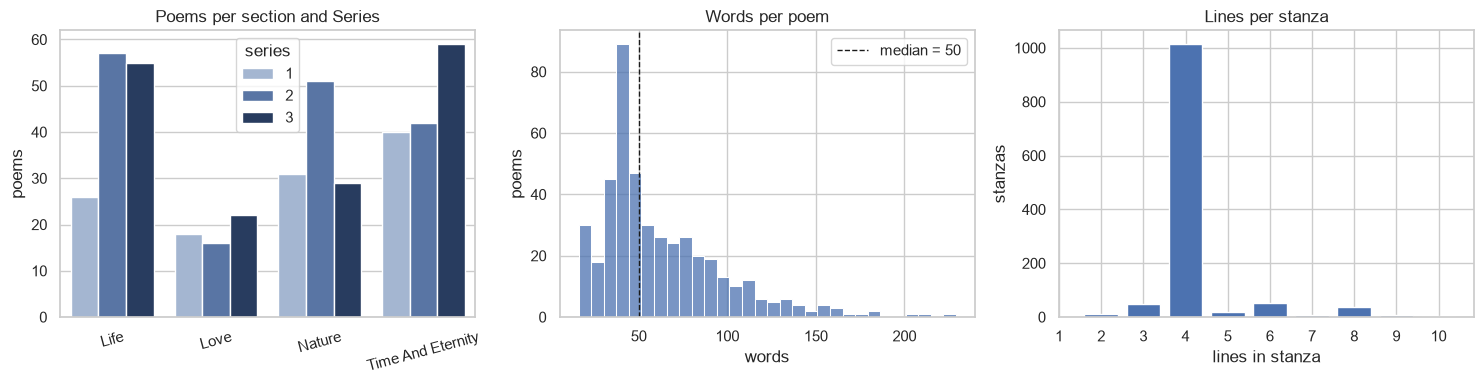

Share of stanzas with exactly 4 lines: 82.6%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sec_order = ["Life", "Love", "Nature", "Time And Eternity"]
sns.countplot(data=poems, x="section", hue="series", order=sec_order, ax=axes[0], palette=["#9DB4D8", "#4C72B0", "#1F3A68"])
axes[0].set(title="Poems per section and Series", xlabel="", ylabel="poems")
axes[0].tick_params(axis="x", rotation=15)
sns.histplot(poems.n_words, bins=30, ax=axes[1], color="#4C72B0")
axes[1].axvline(poems.n_words.median(), color="k", ls="--", lw=1, label=f"median = {poems.n_words.median():.0f}")
axes[1].set(title="Words per poem", xlabel="words", ylabel="poems"); axes[1].legend()
stanza_len = Counter(len([l for l in st.split("\n") if l.strip()]) for t in poems.text for st in t.split("\n\n"))
s = pd.Series(stanza_len).sort_index().loc[1:10]
axes[2].bar(s.index, s.values, color="#4C72B0")
axes[2].set(title="Lines per stanza", xlabel="lines in stanza", ylabel="stanzas", xticks=range(1, 11))
plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_corpus_overview.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Share of stanzas with exactly 4 lines: {stanza_len[4] / sum(stanza_len.values()):.1%}")

In [7]:
# Character inventory and editorial artefacts the model will learn
punct = Counter(c for t in poems.text for c in t if not c.isalnum() and c not in " \n")
print("Punctuation counts:", dict(punct.most_common()))
all_lines = [l for t in poems.text for l in t.split("\n") if l.strip()]
print(f"Lines ending in a dash: {np.mean([l.rstrip().endswith('-') for l in all_lines]):.1%}")
print(f"Lines starting with a capital letter: {np.mean([l[0].isupper() for l in all_lines]):.1%}")
print(f"Mean words per line: {np.mean([len(l.split()) for l in all_lines]):.2f}")
print("\nExample of the editors' dash convention ' --' and archaic contractions:")
for l in [l for l in all_lines if l.endswith("--")][:3] + [l for l in all_lines if "'t is" in l][:2]:
    print("   ", l)

Punctuation counts: {',': 2996, '.': 940, '-': 778, ';': 514, "'": 462, '!': 406, '?': 150, '"': 109, ':': 25, '(': 2, ')': 2, '_': 2}
Lines ending in a dash: 5.0%
Lines starting with a capital letter: 98.4%
Mean words per line: 5.12

Example of the editors' dash convention ' --' and archaic contractions:
    Toll, for the bonnie souls, --
    Some things that fly there be, --
    Some things that stay there be, --
    A precious, mouldering pleasure 't is
    When it goes, 't is like the distance


**Preprocessing considerations (from the inspection above)**
- **Units are whole poems.** The train/validation/test split is made *by poem*, so no poem is partly in training and partly in evaluation. Otherwise held-out perplexity would be inflated by memorized text.
- **Lengths are short and regular.** The median poem has about 50 words, and most stanzas are quatrains (4 lines). A 128-token block holds a typical poem, and the 80-token generation length matches a typical poem.
- **The text is the *editors'* Dickinson.** Todd and Higginson regularized her punctuation, so dashes appear mostly as " --" at line ends. They also added titles and capitalized line starts. The model will learn this edited style, not the manuscripts (see the transcriber's note in the raw file). Titles are kept out of the training text for this reason.
- **Few duplicates.** There are no exact duplicates. Poems that share a first line are reported above. They are separate poems in the edition, so they are kept, but splitting by poem keeps each one whole.
- **Light cleaning only.** Indentation is removed. Line breaks, stanza breaks, archaic spellings ("'t is") and original punctuation are kept as data, because they are part of the style.

### 2.5 Train / validation / test split (by poem, stratified by section)

In [8]:
def split_by_poem(df, fracs, seed):
    rng = np.random.default_rng(seed)
    split = pd.Series("train", index=df.index)
    for _, g in df.groupby("section"):                     # stratify by thematic section
        idx = rng.permutation(g.index.to_numpy())
        n_val, n_test = round(len(idx) * fracs[1]), round(len(idx) * fracs[2])
        split[idx[:n_val]] = "val"
        split[idx[n_val:n_val + n_test]] = "test"
    return split

poems["split"] = split_by_poem(poems, CONFIG["split_frac"], CONFIG["seed"])
poems.drop(columns=[]).to_csv(DATA_DIR / "poems.csv", index=False)
display(pd.crosstab(poems.section, poems.split, margins=True))
print(poems.groupby("split").n_tokens.sum().rename("GPT-2 tokens"))

split,test,train,val,All
section,,,,
Life,14,110,14,138
Love,6,44,6,56
Nature,11,89,11,111
Time And Eternity,14,113,14,141
All,45,356,45,446


split
test      4808
train    33604
val       4660
Name: GPT-2 tokens, dtype: int64


## 3. Model, training and diagnostics (Task 3)

### 3.1 Architecture: GPT-2 small

GPT-2 is a decoder-only Transformer language model. Its architecture, printed in full below, is:

| Component | GPT-2 small |
|---|---|
| Token embedding (`wte`) | 50,257-token byte-level BPE vocabulary → 768-dimensional vectors |
| Position embedding (`wpe`) | learned, 1,024 positions × 768 |
| Transformer blocks (`h`) | **12** identical blocks, each: LayerNorm → **masked multi-head self-attention** (12 heads × 64 dims) → residual add → LayerNorm → **MLP** (768 → 3,072 → 768, GELU) → residual add |
| Final LayerNorm (`ln_f`) | normalizes the last hidden state |
| LM head (`lm_head`) | linear 768 → 50,257 logits, **weight-tied** to the token embedding |

The *causal mask* in self-attention stops each position from seeing future tokens. So the model is trained to predict token *t + 1* from tokens 1…*t*, which is what generation from a first line needs.

In [9]:
set_seed(CONFIG["seed"])
model = GPT2LMHeadModel.from_pretrained(CONFIG["model_name"]).to(device)
tok.pad_token = tok.eos_token
print(model)
cfg = model.config
n_params = sum(p.numel() for p in model.parameters())
print(f"\nlayers={cfg.n_layer}  heads={cfg.n_head}  d_model={cfg.n_embd}  context={cfg.n_positions}  "
      f"vocab={cfg.vocab_size}  activation={cfg.activation_function}")
print(f"parameters: {n_params / 1e6:.1f} M  (LM head tied to token embedding: "
      f"{model.lm_head.weight.data_ptr() == model.transformer.wte.weight.data_ptr()})")

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

layers=12  heads=12

### 3.2 Key design choices

| Choice | Setting | Why |
|---|---|---|
| Base model | GPT-2 small, pretrained | Small data → transfer learning. 124M parameters fine-tune in minutes on a laptop GPU. |
| Tokenizer | GPT-2 byte-level BPE, unchanged | Must match the pretrained embeddings. Byte-level BPE covers archaic forms ("'t is", "learnèd") without unknown tokens. |
| Input format | `<|endoftext|>` + poem, poems **packed** into 128-token blocks | `<|endoftext|>` marks where a poem starts, so at generation time `<|endoftext|>` + first line means "start of a poem". Packing avoids wasting compute on padding. This is the standard GPT-2 training format. |
| Objective | Causal language-model cross-entropy (next-token prediction) | The native GPT-2 objective; no new heads or losses needed. |
| Optimizer | AdamW, lr 5e-5, weight decay 0.01 | Standard for Transformer fine-tuning. Decoupled weight decay regularizes without upsetting Adam's adaptive steps. A small learning rate keeps the pretrained knowledge. |
| Schedule | Linear warm-up (10 % of steps) then linear decay | Avoids large, destabilizing updates in the first steps of fine-tuning. |
| Gradient clipping | max-norm 1.0 | Guards against loss spikes on a small dataset. |
| Epochs / model selection | 8 epochs, keep the **epoch with the lowest validation loss** | The corpus is tiny, so overfitting is expected. Validation loss chooses the stopping point instead of a guess. |

### 3.3 Build the training sequences

In [10]:
def pack(texts, block):
    # Concatenate <eos> + poem for every poem, then cut into equal blocks (remainder dropped).
    ids = []
    for t in texts:
        ids += [tok.eos_token_id] + tok(t + "\n")["input_ids"]
    n = len(ids) // block
    return torch.tensor(ids[: n * block]).view(n, block), len(ids)

blocks = {}
for split in ("train", "val", "test"):
    blocks[split], n_tok = pack(poems.loc[poems.split == split, "text"], CONFIG["block_size"])
    print(f"{split:5s}: {n_tok:6,} tokens -> {blocks[split].shape[0]:3d} blocks of {CONFIG['block_size']}")

print("\nFirst training block, decoded:\n" + "-" * 50)
print(tok.decode(blocks["train"][0]))

train: 34,316 tokens -> 268 blocks of 128
val  :  4,750 tokens ->  37 blocks of 128
test :  4,898 tokens ->  38 blocks of 128

First training block, decoded:
--------------------------------------------------
<|endoftext|>Our share of night to bear,
Our share of morning,
Our blank in bliss to fill,
Our blank in scorning.

Here a star, and there a star,
Some lose their way.
Here a mist, and there a mist,
Afterwards -- day!
<|endoftext|>If I can stop one heart from breaking,
I shall not live in vain;
If I can ease one life the aching,
Or cool one pain,
Or help one fainting robin
Unto his nest again,
I shall not live in vain.
<|endoftext|>Within my reach!


### 3.4 Training loop

The loop is written out in PyTorch rather than using `Trainer`, so each step is visible. Each step: forward pass, cross-entropy loss (HF shifts the labels by one position inside the model), backward pass, gradient clipping, AdamW step, then the LR scheduler step. Validation loss is measured before training (epoch 0, the pretrained model) and after every epoch. The best weights are kept in memory.

In [11]:
@torch.no_grad()
def eval_loss(m, data, batch_size=16):
    m.eval()
    losses = []
    for i in range(0, len(data), batch_size):
        b = data[i:i + batch_size].to(device)
        losses.append(m(b, labels=b).loss.item() * len(b))
    return sum(losses) / len(data)

def train(model, cfg):
    g = torch.Generator().manual_seed(cfg["seed"])
    loader = torch.utils.data.DataLoader(blocks["train"], batch_size=cfg["batch_size"], shuffle=True, generator=g)
    total_steps = len(loader) * cfg["epochs"]
    no_decay = ["bias", "ln_", "ln_f"]
    params = [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": cfg["weight_decay"]},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], "weight_decay": 0.0},
    ]
    opt = torch.optim.AdamW(params, lr=cfg["lr"])
    sched = get_linear_schedule_with_warmup(opt, int(cfg["warmup_frac"] * total_steps), total_steps)

    history, step_log = [], []
    v0 = eval_loss(model, blocks["val"])
    history.append(dict(epoch=0, train_loss=np.nan, val_loss=v0, val_ppl=math.exp(v0), seconds=0.0))
    print(f"epoch 0 (pretrained)  val loss {v0:.4f}  val ppl {math.exp(v0):7.2f}")
    best = dict(val_loss=v0, epoch=0, state=copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()}))

    step = 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); t0 = time.time(); ep_losses = []
        for b in loader:
            b = b.to(device)
            loss = model(b, labels=b).loss
            loss.backward()
            gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"]).item()
            opt.step(); sched.step(); opt.zero_grad(set_to_none=True)
            step += 1
            ep_losses.append(loss.item())
            step_log.append(dict(step=step, epoch=epoch, loss=loss.item(), grad_norm=gnorm, lr=sched.get_last_lr()[0]))
        v = eval_loss(model, blocks["val"])
        tr = float(np.mean(ep_losses))
        history.append(dict(epoch=epoch, train_loss=tr, val_loss=v, val_ppl=math.exp(v), seconds=time.time() - t0))
        flag = ""
        if v < best["val_loss"]:
            best = dict(val_loss=v, epoch=epoch, state=copy.deepcopy({k: t.cpu() for k, t in model.state_dict().items()}))
            flag = "  <- best so far"
        print(f"epoch {epoch}  train loss {tr:.4f}  val loss {v:.4f}  val ppl {math.exp(v):7.2f}  "
              f"({time.time() - t0:4.1f}s){flag}")
    return pd.DataFrame(history), pd.DataFrame(step_log), best

set_seed(CONFIG["seed"])
history, step_log, best = train(model, CONFIG)
final_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}  # epoch-8 weights, kept for section 4.5
model.load_state_dict(best["state"])
model.eval()
print(f"\nRestored weights from epoch {best['epoch']} (val loss {best['val_loss']:.4f}, "
      f"val ppl {math.exp(best['val_loss']):.2f})")
history.to_csv(MET_DIR / "training_history.csv", index=False)
step_log.to_csv(MET_DIR / "training_steps.csv", index=False)

epoch 0 (pretrained)  val loss 5.0620  val ppl  157.91


epoch 1  train loss 4.6361  val loss 4.0957  val ppl   60.08  (18.2s)  <- best so far


epoch 2  train loss 4.0528  val loss 3.9883  val ppl   53.96  (18.4s)  <- best so far


epoch 3  train loss 3.8194  val loss 3.9905  val ppl   54.08  (18.1s)


epoch 4  train loss 3.6758  val loss 4.0044  val ppl   54.84  (18.3s)


epoch 5  train loss 3.5913  val loss 4.0189  val ppl   55.64  (17.7s)


epoch 6  train loss 3.5143  val loss 4.0371  val ppl   56.66  (18.2s)


epoch 7  train loss 3.4645  val loss 4.0444  val ppl   57.08  (18.1s)


epoch 8  train loss 3.4289  val loss 4.0467  val ppl   57.21  (17.8s)

Restored weights from epoch 2 (val loss 3.9883, val ppl 53.96)


### 3.5 Training diagnostics

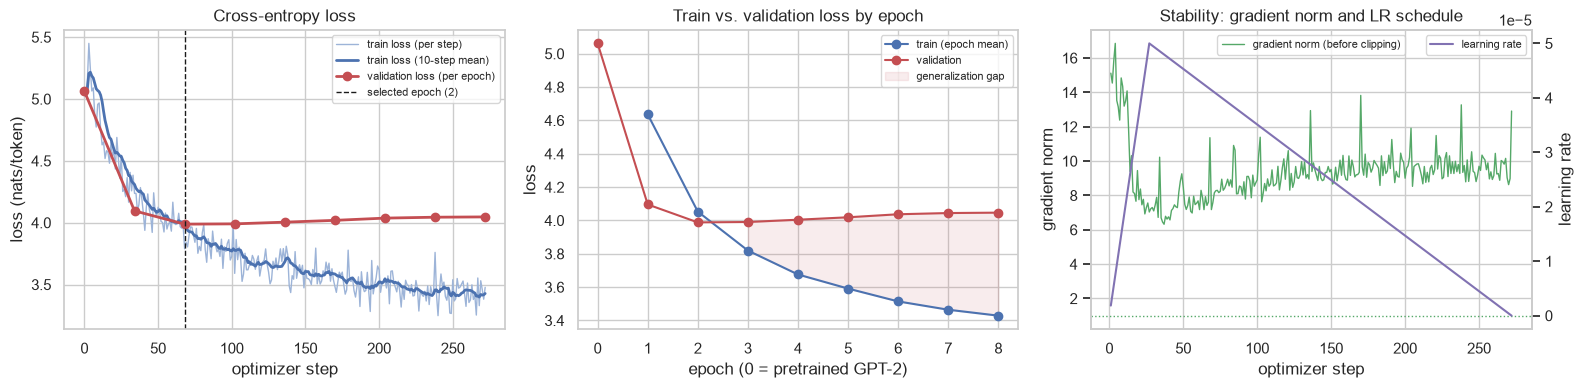

,epoch,train_loss,val_loss,val_ppl,seconds
0,0,NaN,5.0620,157.9072,0.0000
1,1,4.6361,4.0957,60.0826,18.0477
2,2,4.0528,3.9883,53.9607,18.2104
3,3,3.8194,3.9905,54.0837,18.1257
4,4,3.6758,4.0044,54.8387,18.3256
5,5,3.5913,4.0189,55.6421,17.7166
6,6,3.5143,4.0371,56.6606,18.1893
7,7,3.4645,4.0444,57.0751,18.0880
8,8,3.4289,4.0467,57.2107,17.7859


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
steps_per_epoch = step_log.groupby("epoch").step.max()
ax.plot(step_log.step, step_log.loss, color="#9DB4D8", lw=1, label="train loss (per step)")
ax.plot(step_log.step, step_log.loss.rolling(10, min_periods=1).mean(), color="#4C72B0", lw=2, label="train loss (10-step mean)")
ax.plot([0] + steps_per_epoch.tolist(), history.val_loss, "o-", color="#C44E52", lw=2, label="validation loss (per epoch)")
ax.axvline(steps_per_epoch.get(best["epoch"], 0), color="k", ls="--", lw=1, label=f"selected epoch ({best['epoch']})")
ax.set(title="Cross-entropy loss", xlabel="optimizer step", ylabel="loss (nats/token)"); ax.legend(fontsize=8)

ax = axes[1]
h = history[history.epoch > 0]
ax.plot(h.epoch, h.train_loss, "o-", label="train (epoch mean)")
ax.plot(history.epoch, history.val_loss, "o-", color="#C44E52", label="validation")
ax.fill_between(h.epoch, h.train_loss, h.val_loss, where=h.val_loss > h.train_loss, color="#C44E52", alpha=0.1, label="generalization gap")
ax.set(title="Train vs. validation loss by epoch", xlabel="epoch (0 = pretrained GPT-2)", ylabel="loss"); ax.legend(fontsize=8)

ax = axes[2]
ax.plot(step_log.step, step_log.grad_norm, color="#55A868", lw=1, label="gradient norm (before clipping)")
ax.axhline(CONFIG["grad_clip"], color="#55A868", ls=":", lw=1)
ax2 = ax.twinx()
ax2.plot(step_log.step, step_log.lr, color="#8172B2", lw=1.5, label="learning rate"); ax2.grid(False)
ax.set(title="Stability: gradient norm and LR schedule", xlabel="optimizer step", ylabel="gradient norm")
ax2.set_ylabel("learning rate")
ax.legend(loc="upper center", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()
display(history.round(4))

**Observations from training**
- **Fine-tuning works quickly.** Validation perplexity drops from 157.9 (pretrained GPT-2, epoch 0) to 60.1 after one epoch and reaches its minimum of **54.0 at epoch 2**. Most of the gain comes in the first epoch, as expected when a model already knows English and only has to adapt to a style.
- **Overfitting starts at epoch 3.** From epoch 2 to 8, training loss keeps falling (4.05 → 3.43) while validation loss rises (3.99 → 4.05). The model is starting to fit the 356 training poems themselves rather than Dickinson's style in general. That is the expected behavior for about 34,000 training tokens. The epoch-2 weights are therefore restored and used for all generation below. The epoch-8 weights are kept only for the memorization comparison in 4.5.
- **Training is stable.** There are no loss spikes or NaNs. Gradient norms before clipping (6 to 17) are always above the clip threshold of 1.0, so clipping rescales every update. Together with warm-up, this keeps the effective step size small and steady. Each epoch takes about 19 s on the M4 GPU, and the whole run takes about 2.5 minutes.

## 4. Generate and evaluate outputs (Task 4)

The evaluation compares the **fine-tuned** model with the same **pretrained GPT-2 before fine-tuning**. Both get identical prompts and identical decoding settings, so differences come from fine-tuning alone.

### 4.1 Held-out perplexity

Perplexity = exp(mean cross-entropy per token) on the **test** poems, which were never used for training or model selection. Lower means the model finds real, unseen Dickinson poems more predictable.

In [13]:
base_model = GPT2LMHeadModel.from_pretrained(CONFIG["model_name"]).to(device).eval()
ppl = pd.DataFrame([
    dict(model=name, split=s, loss=(l := eval_loss(m, blocks[s])), perplexity=math.exp(l))
    for name, m in (("pretrained GPT-2", base_model), ("fine-tuned GPT-2", model))
    for s in ("val", "test")
])
ppl.to_csv(MET_DIR / "perplexity.csv", index=False)
display(ppl.round(3))
t = ppl[ppl.split == "test"].set_index("model").perplexity
print(f"Test perplexity falls from {t['pretrained GPT-2']:.1f} to {t['fine-tuned GPT-2']:.1f} "
      f"({1 - t['fine-tuned GPT-2'] / t['pretrained GPT-2']:.0%} lower)")

,model,split,loss,perplexity
0,pretrained GPT-2,val,5.062,157.907
1,pretrained GPT-2,test,5.211,183.299
2,fine-tuned GPT-2,val,3.988,53.961
3,fine-tuned GPT-2,test,4.146,63.208


Test perplexity falls from 183.3 to 63.2 (66% lower)


**Interpretation.** On the 45 held-out test poems, perplexity drops from 183.3 to 63.2, which is 66% lower. The fine-tuned model assigns much higher probability to real, unseen Dickinson poems. It has learned something general about the corpus (vocabulary, line shape, punctuation habits), not only the training poems. Validation and test perplexity are close (54.0 vs. 63.2), so the epoch chosen on validation data generalizes to the untouched test split.

### 4.2 Generated samples

**Prompts.** Each prompt is the real first line of a **test** poem, written by Dickinson herself. The model sees `<|endoftext|>` + first line + newline and continues from there. Decoding uses **nucleus (top-p) sampling** with temperature 0.8 and top-p 0.9. Every prompt has its own fixed seed, so any sample can be reproduced.

In [14]:
@torch.no_grad()
def generate(m, first_line, seed, n=1, do_sample=True, max_new_tokens=None, **extra):
    enc = tok(tok.eos_token + first_line + "\n", return_tensors="pt").to(device)
    torch.manual_seed(seed)
    kw = dict(do_sample=True, temperature=CONFIG["temperature"], top_p=CONFIG["top_p"], top_k=0) if do_sample else dict(do_sample=False)
    out = m.generate(**enc, max_new_tokens=max_new_tokens or CONFIG["max_new_tokens"], num_return_sequences=n,
                     pad_token_id=tok.eos_token_id, **kw, **extra)
    texts = []
    for seq in out:
        new = seq[enc["input_ids"].shape[1]:].tolist()
        finished = tok.eos_token_id in new
        if finished:
            new = new[: new.index(tok.eos_token_id)]
        texts.append((tok.decode(new).strip("\n"), finished))
    return texts

test_poems = poems[poems.split == "test"].reset_index(drop=True)
rows = []
for i, r in test_poems.iterrows():
    for name, m in (("pretrained", base_model), ("fine-tuned", model)):
        (txt, fin), = generate(m, r.first_line, seed=1000 + i)
        rows.append(dict(prompt_id=i, poem_id=r.poem_id, prompt=r.first_line, model=name, decoding="nucleus",
                         text=txt, ended_with_eos=fin))
gens = pd.DataFrame(rows)
gens.to_csv(GEN_DIR / "test_prompt_generations.csv", index=False)
print(f"{len(gens)} generations ({len(test_poems)} test prompts x 2 models)")

90 generations (45 test prompts x 2 models)


In [15]:
def show(prompt_id, models=("pretrained", "fine-tuned")):
    r = test_poems.loc[prompt_id]
    print("=" * 78)
    print(f"[prompt {prompt_id}]  {r.first_line}")
    for name in models:
        g = gens[(gens.prompt_id == prompt_id) & (gens.model == name)].iloc[0]
        print(f"\n--- {name} GPT-2 ---")
        print(g.text)
    print("\n--- real continuation (Dickinson, held out) ---")
    print(r.text.split("\n", 1)[1] if "\n" in r.text else "")

for pid in [0, 5, 10, 20, 30, 40]:
    show(pid)

[prompt 0]  Success is counted sweetest

--- pretrained GPT-2 ---
(The score is calculated as the average score in every match played, and is not the final score. The last game score is the score in the last game for all matches played in a season. The score will be not shown on the scoreboard until it has been completed by the match's host)

If you are not a fan of a particular team, you can see in the upper

--- fine-tuned GPT-2 ---
As if it had been a storm.

--- real continuation (Dickinson, held out) ---
By those who ne'er succeed.
To comprehend a nectar
Requires sorest need.

Not one of all the purple host
Who took the flag to-day
Can tell the definition,
So clear, of victory,

As he, defeated, dying,
On whose forbidden ear
The distant strains of triumph
Break, agonized and clear!
[prompt 5]  Some keep the Sabbath going to church;

--- pretrained GPT-2 ---
Some keep it as a thing of the past;

Others do it by their spirit;

Some go beyond their own limitations.

One may be an imp

**Several samples for one prompt** show how much the outputs vary. Here are three fine-tuned samples with different seeds for the same first line:

In [16]:
multi_prompt = test_poems.loc[12, "first_line"]
print(f"Prompt: {multi_prompt}\n")
for k, (txt, _) in enumerate(generate(model, multi_prompt, seed=7, n=3), 1):
    print(f"--- sample {k} ---\n{txt}\n")

Prompt: I lost a world the other day.



--- sample 1 ---
It was an eagle in the dusk.
It is still the bird I'll never know.
It has a castle in the hills,
I never met there;
And the tower of the fair
I've never seen in the world;

But of the short-haired peasant,
The wise, the good,
The wayward, the immortal
I am afraid
To

--- sample 2 ---
And now the thief will go.

He'll steal my name!

I lose my honor.

--- sample 3 ---
I lost a world the other day,
I lost a world the other day.

I lost a world the other day,
I lost a world the other day,
I lost a world the other day,
I lost a world the other day,
I lost a world the other day,
I lost a world the other day,
I lost a world the other day



### 4.3 Style statistics

Simple, transparent statistics are computed on each generated continuation and on the **real held-out continuations** (the test poems without their first line). If fine-tuning worked, the fine-tuned model's numbers should move from the pretrained model's toward the real poems.

| Statistic | What it captures |
|---|---|
| words per line | Dickinson's short, hymn-meter lines |
| lines per stanza, % of samples with a stanza break | quatrain structure |
| % lines ending in a dash | the editors' " --" punctuation |
| % lines starting with a capital | verse layout (not prose) |
| repeated-trigram rate | degenerate repetition within a sample (lower is better) |
| distinct-2 (across samples) | diversity: unique word bigrams / all bigrams |

In [17]:
WORD = re.compile(r"[A-Za-z']+")

def style_stats(text):
    lines = [l for l in text.split("\n") if l.strip()]
    stanzas = [s for s in text.split("\n\n") if s.strip()]
    words = [w.lower() for w in WORD.findall(text)]
    tri = list(zip(words, words[1:], words[2:]))
    return dict(
        n_lines=len(lines),
        words_per_line=np.mean([len(l.split()) for l in lines]) if lines else np.nan,
        lines_per_stanza=len(lines) / max(len(stanzas), 1),
        has_stanza_break=len(stanzas) > 1,
        dash_line_end=np.mean([l.rstrip().endswith("-") for l in lines]) if lines else np.nan,
        capital_line_start=np.mean([l.lstrip()[0].isupper() for l in lines]) if lines else np.nan,
        repeated_trigram_rate=1 - len(set(tri)) / len(tri) if tri else 0.0,
    )

def distinct_n(texts, n=2):
    grams = [tuple(w[i:i + n]) for t in texts for w in [WORD.findall(t.lower())] for i in range(len(w) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)

real = pd.DataFrame(dict(model="real (held-out)", text=[t.split("\n", 1)[1] for t in test_poems.text]))
sets = pd.concat([real, gens[gens.decoding == "nucleus"][["model", "text"]]], ignore_index=True)
stats = pd.concat([sets, sets.text.apply(style_stats).apply(pd.Series)], axis=1)
order = ["real (held-out)", "pretrained", "fine-tuned"]
style_table = stats.groupby("model")[["n_lines", "words_per_line", "lines_per_stanza", "has_stanza_break",
                                      "dash_line_end", "capital_line_start", "repeated_trigram_rate"]].mean().loc[order]
style_table["distinct_2"] = [distinct_n(sets[sets.model == k].text) for k in order]
style_table.to_csv(MET_DIR / "style_statistics.csv")
display(style_table.round(3))

,n_lines,words_per_line,lines_per_stanza,has_stanza_break,dash_line_end,capital_line_start,repeated_trigram_rate,distinct_2
model,,,,,,,,
real (held-out),12.222,5.052,4.898,0.867,0.047,0.993,0.004,0.921
pretrained,7.089,12.078,1.000,0.956,0.004,0.798,0.209,0.663
fine-tuned,4.867,5.600,3.011,0.400,0.013,0.956,0.126,0.657


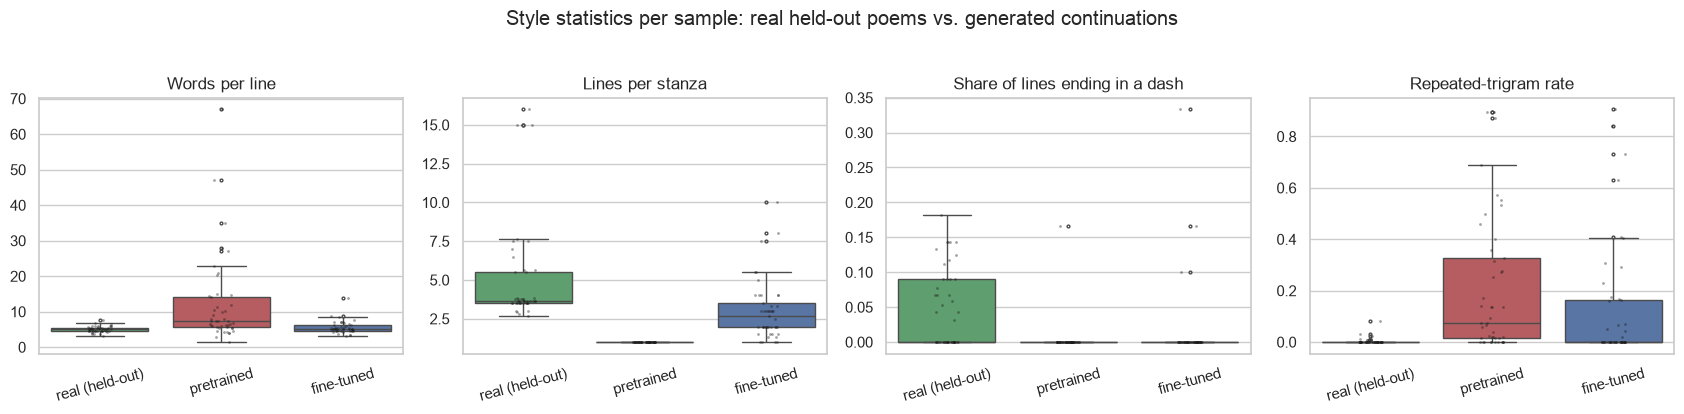

In [18]:
plot_cols = [("words_per_line", "Words per line"), ("lines_per_stanza", "Lines per stanza"),
             ("dash_line_end", "Share of lines ending in a dash"), ("repeated_trigram_rate", "Repeated-trigram rate")]
palette = {"real (held-out)": "#55A868", "pretrained": "#C44E52", "fine-tuned": "#4C72B0"}
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, title) in zip(axes, plot_cols):
    sns.boxplot(data=stats, x="model", y=col, order=order, palette=palette, hue="model", legend=False, ax=ax, fliersize=2)
    sns.stripplot(data=stats, x="model", y=col, order=order, color="k", size=2, alpha=0.4, ax=ax)
    ax.set(title=title, xlabel="", ylabel=""); ax.tick_params(axis="x", rotation=15)
plt.suptitle("Style statistics per sample: real held-out poems vs. generated continuations", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_style_statistics.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretation of the style statistics (table and Figure 3)**
- **Line shape moved strongly toward Dickinson.** Words per line went from 12.1 (pretrained) to 5.6 (fine-tuned), against 5.1 in the real poems. Lines starting with a capital went from 79.8% to 95.6% (real: 99.3%). The pretrained model writes prose or one-sentence paragraphs. The fine-tuned model writes verse lines.
- **Stanza structure is only partly learned.** Fine-tuned outputs average 3.0 lines per stanza (real: 4.9). Only 40% contain a stanza break at all (real: 87%), because most outputs stop after a few lines. The pretrained model's 1.0 lines per stanza and 96% "stanza breaks" come from putting a blank line after every line, which is a prose habit, not a stanza.
- **Outputs are too short.** Fine-tuned continuations average 4.9 lines against 12.2 for the real poems, and 76% end with an end-of-poem token before the 80-token limit. The model has learned to end poems but ends them too early.
- **The dash is under-produced.** 1.3% of fine-tuned lines end in a dash, against 4.7% in the real poems. The signature punctuation is learned weakly.
- **Repetition is the main weakness.** The repeated-trigram rate (12.6%) is better than the pretrained model's (20.9%) but far above the real poems (0.4%). Diversity (distinct-2 = 0.66) is no better than the pretrained model and well below the real poems (0.92). Section 4.4 looks at this failure.

### 4.4 Decoding strategy and a failure case: greedy repetition

The fine-tuned model stays the same; only the decoding changes:
- **greedy**: always take the most likely token. Maximization-based decoding is known to produce repetitive, degenerate text.
- **nucleus**: the evaluation setting from 4.2 (T = 0.8, top-p = 0.9).
- **nucleus + no-repeat-3gram**: the same sampling, but no word trigram (3-token sequence) may occur twice in one output. This tests a simple mitigation for the repetition that also shows up under nucleus sampling in 4.2.

In [19]:
greedy_rows = []
for i, r in test_poems.iterrows():
    (txt, fin), = generate(model, r.first_line, seed=0, do_sample=False)
    greedy_rows.append(dict(prompt_id=i, poem_id=r.poem_id, prompt=r.first_line, model="fine-tuned",
                            decoding="greedy", text=txt, ended_with_eos=fin))
greedy = pd.DataFrame(greedy_rows)
norep = pd.DataFrame([
    dict(prompt_id=i, poem_id=r.poem_id, prompt=r.first_line, model="fine-tuned", decoding="nucleus + no-repeat-3gram",
         text=(g := generate(model, r.first_line, seed=1000 + i, no_repeat_ngram_size=3)[0])[0], ended_with_eos=g[1])
    for i, r in test_poems.iterrows()])
pd.concat([greedy, norep]).to_csv(GEN_DIR / "test_prompt_generations_decoding_variants.csv", index=False)

dec = pd.concat([gens[gens.model == "fine-tuned"], greedy, norep], ignore_index=True)
dec = pd.concat([dec, dec.text.apply(style_stats).apply(pd.Series)], axis=1)
dec_table = dec.groupby("decoding").agg(
    repeated_trigram_rate=("repeated_trigram_rate", "mean"),
    share_samples_with_repetition_over_20pct=("repeated_trigram_rate", lambda s: (s > 0.2).mean()),
    ended_with_eos=("ended_with_eos", "mean"),
)
dec_table["mean_lines"] = dec.groupby("decoding").n_lines.mean()
dec_table["distinct_2"] = [distinct_n(dec[dec.decoding == k].text) for k in dec_table.index]
dec_table = dec_table.loc[["greedy", "nucleus", "nucleus + no-repeat-3gram"]]
dec_table.to_csv(MET_DIR / "decoding_comparison.csv")
display(dec_table.round(3))

worst = greedy.assign(rep=greedy.text.apply(lambda t: style_stats(t)["repeated_trigram_rate"])).sort_values("rep", ascending=False)
for _, r in worst.head(2).iterrows():
    print("=" * 78)
    print(f"[prompt {r.prompt_id}, greedy, repeated-trigram rate {r.rep:.2f}]  {r.prompt}\n{r.text}")
    print(f"\n--- same prompt, nucleus sampling ---\n{gens[(gens.prompt_id == r.prompt_id) & (gens.model == 'fine-tuned')].text.iloc[0]}")
    print(f"\n--- same prompt, nucleus + no-repeat-3gram ---\n{norep[norep.prompt_id == r.prompt_id].text.iloc[0]}")

,repeated_trigram_rate,share_samples_with_repetition_over_20pct,ended_with_eos,mean_lines,distinct_2
decoding,,,,,
greedy,0.753,0.867,0.133,9.622,0.114
nucleus,0.126,0.200,0.756,4.867,0.657
nucleus + no-repeat-3gram,0.002,0.000,0.889,4.533,0.849


[prompt 6, greedy, repeated-trigram rate 0.94]  A something in a summer's day,
A little bird, a little bird,
A little bird, a little bird,
A little bird, a little bird,
A little bird, a little bird,
A little bird, a little bird,
A little bird, a little bird,
A little bird, a little bird,
A little bird, a little bird,
A little bird, a little bird,

--- same prompt, nucleus sampling ---
A gathering of the summer's boughs,
A fence and an arrow,

A clock and a stooge,
A bird and a dove;

--- same prompt, nucleus + no-repeat-3gram ---
A gathering of the summer's boughs,
And, in one little summer's night,
He was so distinguished.
[prompt 39, greedy, repeated-trigram rate 0.93]  The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,
The cricket sang,

--- same pro

**Interpretation.** Greedy decoding fails badly. 87% of greedy outputs repeat more than a fifth of their trigrams, and the typical output is one phrase looped to the token limit ("A little bird, a little bird," / "The cricket sang,"). Only 13% of greedy outputs ever reach an end-of-poem token. This is the degeneration that maximization-based decoding is known to cause, and it is why nucleus sampling is used for evaluation. Nucleus sampling helps but does not cure it: 20% of its samples still pass the 20% repetition threshold, often by **echoing the prompt line** (prompt 5 above, and sample 3 for "I lost a world the other day."). Blocking repeated trigrams at decoding time almost removes repetition (0.2%) and raises diversity from 0.66 to 0.85, close to the real poems' 0.92. Outputs stay short (4.5 lines). So repetition is mostly a *decoding* problem, while shortness is a *model* problem.

### 4.5 Memorization check

A model fine-tuned on a small corpus for several epochs may **reproduce its training text** instead of generating new text. That matters both for judging quality (is it creating or copying?) and for the ethics of creative ownership. Three models are compared:
- **pretrained**: GPT-2 before fine-tuning. Has it already seen these famous poems in its web pretraining data?
- **fine-tuned (epoch 2)**: the model selected by validation loss and used everywhere above.
- **overfit (epoch 8)**: the same run's final weights, after six more epochs of falling training loss and rising validation loss.

Three checks:
1. **Membership gap.** Perplexity on the *training* poems vs. the held-out *test* poems. A model that has memorized its training data finds those poems much more predictable than unseen ones by the same author.
2. **Copying in normal generation.** For each sampled continuation of a test prompt, the longest run of consecutive words that also appears anywhere in the training poems. The same measure on the **real held-out poems** gives the "natural" overlap, since poems by one author share short phrases.
3. **Extraction probe.** For 40 *training* poems, prompt with the real first line and decode greedily, with trigram repetition blocked so the probe is not swamped by the loops seen in 4.4. The score is how many words of the true continuation are reproduced exactly.

In [20]:
overfit_model = GPT2LMHeadModel.from_pretrained(CONFIG["model_name"]).to(device)
overfit_model.load_state_dict(final_state)
overfit_model.eval()
MODELS = {"pretrained": base_model, "fine-tuned (epoch 2)": model, "overfit (epoch 8)": overfit_model}

membership = pd.DataFrame([
    dict(model=name, train_ppl=math.exp(eval_loss(m, blocks["train"])), test_ppl=math.exp(eval_loss(m, blocks["test"])))
    for name, m in MODELS.items()])
membership["test_to_train_ratio"] = membership.test_ppl / membership.train_ppl
membership.to_csv(MET_DIR / "membership_gap.csv", index=False)
display(membership.round(2))

,model,train_ppl,test_ppl,test_to_train_ratio
0,pretrained,163.41,183.30,1.12
1,fine-tuned (epoch 2),41.74,63.21,1.51
2,overfit (epoch 8),25.90,67.90,2.62


In [21]:
train_words = [w.lower() for t in poems.loc[poems.split == "train", "text"] for w in WORD.findall(t)]
MAX_N = 30
train_ngrams = {n: set(zip(*[train_words[i:] for i in range(n)])) for n in range(1, MAX_N + 1)}

def longest_copied_span(text):
    w = [x.lower() for x in WORD.findall(text)]
    best = 0
    for n in range(1, min(MAX_N, len(w)) + 1):
        if any(g in train_ngrams[n] for g in zip(*[w[i:] for i in range(n)])):
            best = n
        else:
            break
    return best

def copied_span_text(text, n):
    w = WORD.findall(text)
    return next((" ".join(w[i:i + n]) for i in range(len(w) - n + 1)
                 if tuple(x.lower() for x in w[i:i + n]) in train_ngrams[n]), "")

overfit_gens = pd.DataFrame([
    dict(prompt_id=i, model="overfit (epoch 8)", text=generate(overfit_model, r.first_line, seed=1000 + i)[0][0])
    for i, r in test_poems.iterrows()])
overfit_gens.to_csv(GEN_DIR / "test_prompt_generations_overfit_epoch8.csv", index=False)

mem = pd.concat([sets.replace({"model": {"fine-tuned": "fine-tuned (epoch 2)"}}), overfit_gens[["model", "text"]]],
                ignore_index=True)
mem["longest_copied_span"] = mem.text.apply(longest_copied_span)
mem_order = ["real (held-out)", "pretrained", "fine-tuned (epoch 2)", "overfit (epoch 8)"]
mem_table = mem.groupby("model").longest_copied_span.agg(["mean", "median", "max"]).loc[mem_order]
mem_table["share_with_span_6plus"] = mem.groupby("model").longest_copied_span.apply(lambda s: (s >= 6).mean()).loc[mem_order]
mem_table.to_csv(MET_DIR / "memorization_spans.csv")
display(mem_table.round(2))

for name in ["fine-tuned (epoch 2)", "overfit (epoch 8)"]:
    print(f"\nLongest copied spans, {name}:")
    for _, r in mem[mem.model == name].sort_values("longest_copied_span", ascending=False).head(3).iterrows():
        print(f"  {r.longest_copied_span} words: \"{copied_span_text(r.text, r.longest_copied_span)}\"")

,mean,median,max,share_with_span_6plus
model,,,,
real (held-out),2.73,3.0,4,0.0
pretrained,2.71,3.0,3,0.0
fine-tuned (epoch 2),2.78,3.0,4,0.0
overfit (epoch 8),2.87,3.0,4,0.0



Longest copied spans, fine-tuned (epoch 2):
  4 words: "as far as the"
  4 words: "How many times they"
  4 words: "And then I heard"

Longest copied spans, overfit (epoch 8):
  4 words: "as far as the"
  4 words: "me I could not"
  4 words: "And then I heard"


In [22]:
def first_line_extraction(m, df, n_probe=40, seed=CONFIG["seed"]):
    out = []
    for _, r in df.sample(n_probe, random_state=seed).iterrows():
        rest = r.text.split("\n", 1)[1]
        true_rest = WORD.findall(rest.lower())
        (gen, _), = generate(m, r.first_line, seed=0, do_sample=False, max_new_tokens=40, no_repeat_ngram_size=3)
        g = WORD.findall(gen.lower())
        k = 0
        while k < min(len(g), len(true_rest)) and g[k] == true_rest[k]:
            k += 1
        n_second = len(WORD.findall(rest.split("\n")[0]))
        out.append(dict(poem_id=r.poem_id, first_line=r.first_line, true_second_line=rest.split("\n")[0],
                        matched_words=k, second_line_exact=k >= n_second, generated=gen))
    return pd.DataFrame(out)

train_poems = poems[poems.split == "train"]
probe = pd.concat([first_line_extraction(m, train_poems).assign(model=name) for name, m in MODELS.items()])
probe.to_csv(MET_DIR / "extraction_probe.csv", index=False)
probe_table = probe.groupby("model").agg(mean_matched_words=("matched_words", "mean"),
                                         max_matched_words=("matched_words", "max"),
                                         share_second_line_exact=("second_line_exact", "mean")).loc[list(MODELS)]
display(probe_table.round(3))

for name in MODELS:
    best_case = probe[probe.model == name].sort_values("matched_words", ascending=False).iloc[0]
    print(f"\n[{name}] strongest case: {best_case.poem_id}, {best_case.matched_words} words matched")
    print(f"  prompt:      {best_case.first_line}\n  true line 2: {best_case.true_second_line}")
    print("  generated:   " + best_case.generated.replace(chr(10), " / ")[:160])

,mean_matched_words,max_matched_words,share_second_line_exact
model,,,
pretrained,0.050,1,0.0
fine-tuned (epoch 2),0.025,1,0.0
overfit (epoch 8),0.125,1,0.0



[pretrained] strongest case: S3-Life-XXXVII, 1 words matched
  prompt:      I had a daily bliss
  true line 2: I half indifferent viewed,
  generated:   I had the same dream /  / And I had the dream / . /  / The dream was a dream. / . /  /  / I was a little girl /  / When I was a kid

[fine-tuned (epoch 2)] strongest case: S1-Natu-VIII, 1 words matched
  prompt:      Some rainbow coming from the fair!
  true line 2: Some vision of the world Cashmere
  generated:   Some rainbow from the sea! /  / Some purple from the sky! / A rainbow from heaven!

[overfit (epoch 8)] strongest case: S1-Time-XL, 1 words matched
  prompt:      I never lost as much but twice,
  true line 2: And that was in the sod;
  generated:   And I never lost so much as once, / I never gained as much as twice, -- / I lost as little as twice as often, / But I never gained so much, / As I


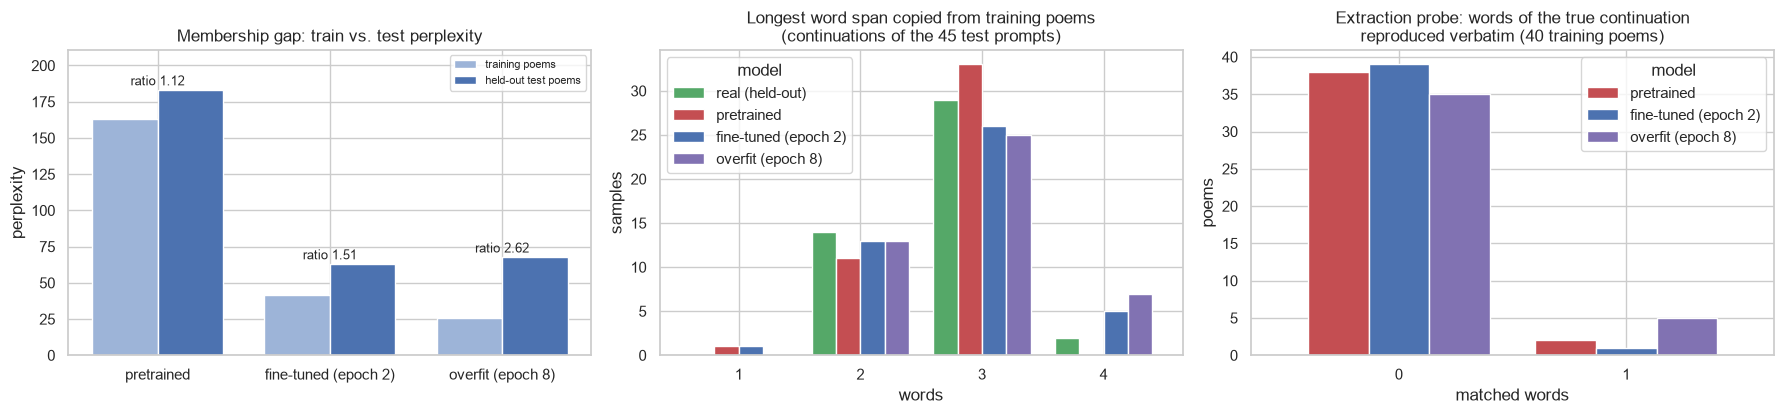

In [23]:
mem_palette = {"real (held-out)": "#55A868", "pretrained": "#C44E52", "fine-tuned (epoch 2)": "#4C72B0", "overfit (epoch 8)": "#8172B2"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
x = np.arange(len(membership)); w = 0.38
axes[0].bar(x - w / 2, membership.train_ppl, w, label="training poems", color="#9DB4D8")
axes[0].bar(x + w / 2, membership.test_ppl, w, label="held-out test poems", color="#4C72B0")
for i, r in membership.iterrows():
    axes[0].text(i, max(r.train_ppl, r.test_ppl) + 3, f"ratio {r.test_to_train_ratio:.2f}", ha="center", fontsize=9)
axes[0].set(xticks=x, xticklabels=membership.model, ylabel="perplexity", title="Membership gap: train vs. test perplexity",
            ylim=(0, membership.test_ppl.max() * 1.15))
axes[0].legend(fontsize=8)
pd.crosstab(mem.longest_copied_span, mem.model)[mem_order].plot.bar(
    ax=axes[1], color=[mem_palette[k] for k in mem_order], rot=0, width=0.8)
axes[1].set(title="Longest word span copied from training poems\n(continuations of the 45 test prompts)", xlabel="words", ylabel="samples")
pd.crosstab(probe.matched_words, probe.model)[list(MODELS)].plot.bar(
    ax=axes[2], color=[mem_palette[k] for k in MODELS], rot=0, width=0.8)
axes[2].set(title="Extraction probe: words of the true continuation\nreproduced verbatim (40 training poems)",
            xlabel="matched words", ylabel="poems")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_memorization.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretation (Figure 4)**
- **No verbatim copying in generated text.** The longest run of words copied from the training poems is at most 4 words for every model, the same as the *real* held-out poems (max 4). No sample from any model has a copied span of 6+ words. The longest spans are common phrases ("as far as the", "And then I heard"), not lines of Dickinson's poetry.
- **No extraction from a first line.** Prompted with the first line of 40 training poems, no model reproduces the true second line. The best case is one matching word. The pretrained model also shows no sign of having memorized these poems from its web pretraining: given "Success is counted sweetest", one of Dickinson's best-known openings, it wrote about sports scores (4.2).
- **But the membership gap grows with training.** The pretrained model finds test poems 1.12× as perplexing as training poems, which is the natural difficulty difference between the two sets. The selected epoch-2 model raises this to 1.51×, and the overfit epoch-8 model to **2.62×**. Its training-poem perplexity of 25.9 is far below its test perplexity of 67.9. The probabilities therefore encode specific training poems more and more with each epoch, even before that shows up as copied text. Under the same probe the epoch-8 model also matches one word in 5 of 40 poems, against 1 of 40 for epoch 2.
- **Conclusion.** At the selected epoch, the model imitates rather than copies. Early stopping on validation loss is therefore also a responsible-use measure. Training longer would raise memorization risk while making held-out perplexity *worse*.

### 4.6 Qualitative evaluation

Judged across all the samples above (6 side-by-side prompts, 3 seeds for one prompt, and the 45-prompt sets behind the statistics):

**Strengths**
- **It writes verse, not prose.** The clearest change from fine-tuning. The pretrained model turns "Success is counted sweetest" into a paragraph about match scores, and the opening of a letter poem ("GOING to him! Happy letter!") into a story about a ship's captain with a gun. The fine-tuned model answers the same prompts with short, capitalized lines.
- **The register and imagery are Dickinson-like.** Nature and religious vocabulary, exclamations and dashes appear in its own new combinations. Examples: "Till you feel it, or -- / A little less, / Too little, too soon!" (prompt 20), "And I prayed for the gods / Upon the lawn." (prompt 30), and in the extraction probe, "Some rainbow from the sea! / Some purple from the sky!". These lines are new. Section 4.5 confirms they are not copied.
- **It sometimes keeps a stanza.** Sample 1 for "I lost a world the other day." runs 11 lines with a stanza break and a consistent speaker ("It was an eagle in the dusk. / It is still the bird I'll never know.").

**Failure cases**
- **Repetition and prompt echo.** "Some keep the Sabbath going to church;" is continued by repeating that exact line three times. Sample 3 for "I lost a world the other day." loops the prompt for the whole output. Under greedy decoding this becomes the rule (87% of outputs, see 4.4).
- **Too short to develop an idea.** Prompt 0 gets a single line ("As if it had been a storm."), while the real poem builds a 12-line argument about success and defeat. On average outputs are 40% of the real length.
- **Weak global coherence.** The images do not build toward a point. In prompt 20 the lines move from a letter to "heirlooms" to "A florid hare / A flower with eyes so long". The real continuation develops one conceit, the letter as a messenger, over three stanzas. Rhyme is rare and accidental (prompt 30: "gods" / "lawn").
- **Repeating its own lines inside a poem.** Prompt 10 alternates two lines ("And the sky brought such a vision / The sky upon them") instead of moving forward.

**Variability.** Outputs vary a lot between seeds for the same prompt. The three samples for "I lost a world the other day." are an 11-line poem, a 3-line fragment, and a degenerate loop. A single sample is therefore not representative, which is why every statistic in this notebook is computed over 45 prompts.

**Overall:** fine-tuning reliably transfers the *surface* of the style: line length, capitalization, register and vocabulary. Held-out perplexity falls by two thirds, and the generated text is new rather than copied. It does not transfer the *structure* of a Dickinson poem: full quatrains, slant rhyme, and a single idea carried to a turn at the end. Repetition is the main failure, and mostly a decoding problem.

## 5. Notebook summary (Task 5)

This project fine-tuned a pretrained GPT-2 small (124M parameters) with a hand-written PyTorch loop on 356 of Emily Dickinson's 446 poems (Project Gutenberg #12242), to continue a poem from its real first line. Validation loss chose epoch 2, which cut held-out test perplexity from 183.3 to 63.2. The generated outputs moved from prose to short, capitalized verse lines (5.6 words per line vs. 5.1 in the real poems), with Dickinson's register and imagery and no verbatim copying beyond 4-word common phrases. The main training challenge was the tiny corpus: overfitting began at epoch 3, and the memorization signal (test-to-train perplexity ratio) rose from 1.51 at epoch 2 to 2.62 at epoch 8, so early stopping also served as a safeguard. The main failure modes were repetition, especially echoing the prompt line (87% of greedy outputs and 20% of nucleus samples were degenerate, nearly fixed by blocking repeated trigrams), and outputs too short and loosely connected to develop the single idea a real Dickinson poem carries.